**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/12_bayesian_regression_and_glms.ipynb)** | **📖 [Conceptual](../conceptual/12_bayesian_regression_and_glms.ipynb)** | **🔵 [R](../r/12_bayesian_regression_and_glms.ipynb)** | **⬅️ [Prev: Ch 11: Two-Group t-Test (Freq vs. Bayes)](11_t_test_frequentist_vs_bayesian.ipynb)** | **➡️ [Next: Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)**

*🧭 Part III: Applied Modeling, Regression, Hierarchy & Model Comparison — Chapter 12 of 22*

---

# Chapter 12: Bayesian Linear Regression, Poisson-Gamma Counts & GLMs
### *The Moving Bell Curve, Exact Rate Conjugacy, Centered Geometry,*
### *and Two Uncertainty Ribbons*

---

## 🧭 The Learning Progression
* **Previous**: Comparing discrete group means (A/B testing,
  hierarchical models).
* **👉 Chapter 12 (You are here)**: Modeling continuous functional relationships
  $\mu(x) = \alpha + \beta x$, event count rates with Poisson-Gamma, and
  bounded probabilities with Logistic GLMs.
* **Next**: Model comparison, cross-validation, and information criteria
  (WAIC, LOO-CV).

---

## Table of Contents
1. **Part 1: From Static Means to Conditional Models**
   $\mu(x) = \alpha + \beta x$
2. **Part 2: The Third Conjugate Pillar — Poisson-Gamma Event Rates**
3. **Part 3: Bayesian Linear Regression & The Geometry of Centering**
4. **Part 4: Generalized Linear Models (GLMs) & Bayesian Logistic Regression**
5. **Part 5: 3-Tier Scaffolding Exercises**


## Part 1: From Static Group Means to Conditional Models

In earlier sheets, we estimated the static mean of a single population
or compared two discrete groups ($A$ vs. $B$).
In production engineering, however, physical metrics do not live in
isolated categorical buckets: response latency varies continuously with
incoming request load (QPS), and failure rates vary continuously with
operating temperature.

### 🔦 The Physical Analogy: The Moving Spotlight on Rails
Imagine an automated gantry crane sliding along an overhead rail above
a production conveyor:
* **The Rail ($\mu(x) = \alpha + \beta x$)**: The expected response changes
  linearly with external load $x$.
* **The Spotlight Carriage**: As load $x$ shifts, the carriage slides along
  the rail, positioning the center of the bell curve at height $\mu(x)$.
* **The Scatter Beam ($\sigma$)**: Individual measurements do not land
  exactly on the rail; thread scheduling, network jitter, and cache
  contention disperse requests around $\mu(x)$ according to Gaussian
  spread $\mathcal{N}(0, \sigma^2)$.


## Part 2: The Third Conjugate Pillar — Poisson-Gamma for Event Rates

Before fitting continuous regression lines, we master the third pillar
of exact analytical conjugacy:
1. **Beta-Binomial**: Discrete binary trials ($p \in [0, 1]$).
2. **Normal-Normal**: Continuous real-valued measurements ($y \in \mathbb{R}$).
3. **Poisson-Gamma**: Event counts over continuous exposure
   ($k \sim \text{Poisson}(\lambda T)$ with $\lambda > 0$).

### Exact Analytical Updating
For rare events occurring at rate $\lambda$ over exposure duration $T$:
$$P(k \mid \lambda, T) = \frac{(\lambda T)^k e^{-\lambda T}}{k!}
\propto \lambda^k e^{-\lambda T}$$

With conjugate prior $\lambda \sim \text{Gamma}(\alpha_0, \beta_0)$ where
$\mathbb{E}[\lambda] = \alpha_0 / \beta_0$:
$$\alpha_{\text{post}} = \alpha_0 + k, \qquad
\beta_{\text{post}} = \beta_0 + T$$

$$\mathbb{E}[\lambda \mid k, T] = \frac{\alpha_0 + k}{\beta_0 + T}, \qquad
\text{Var}(\lambda \mid k, T) = \frac{\alpha_0 + k}{(\beta_0 + T)^2}$$


In [1]:
# --- Step 1: Exact Poisson-Gamma Updating for Incident Rates ---
import numpy as np
from scipy.stats import gamma

# Prior: Gamma(alpha_0, beta_0)
# alpha_0 = 2 pseudo-events, beta_0 = 5 pseudo-hours
alpha_0 = 2.0
beta_0 = 5.0
prior_mean = alpha_0 / beta_0
prior_std = np.sqrt(alpha_0) / beta_0

# Observation: k = 4 incidents over T = 10 hours
k_obs = 4.0
T_obs = 10.0

# Exact conjugate posterior parameters
alpha_post = alpha_0 + k_obs
beta_post = beta_0 + T_obs
post_mean = alpha_post / beta_post
post_std = np.sqrt(alpha_post) / beta_post
ci_95 = gamma.ppf([0.025, 0.975], a=alpha_post, scale=1.0 / beta_post)

print(f"Prior:     Gamma(alpha={alpha_0:.1f}, beta={beta_0:.1f})")
print(f"Prior Mean: {prior_mean:.4f} events/hr, Std: {prior_std:.4f}")
print(f"Observed:  k = {k_obs:.0f} events over T = {T_obs:.1f} hours")
print(f"Posterior: Gamma(alpha={alpha_post:.1f}, beta={beta_post:.1f})")
print(f"Post Mean:  {post_mean:.4f} events/hr, Std: {post_std:.4f}")
print(f"95% Equal-Tailed Credible Interval: [{ci_95[0]:.4f}, {ci_95[1]:.4f}]")


Prior:     Gamma(alpha=2.0, beta=5.0)
Prior Mean: 0.4000 events/hr, Std: 0.2828
Observed:  k = 4 events over T = 10.0 hours
Posterior: Gamma(alpha=6.0, beta=15.0)
Post Mean:  0.4000 events/hr, Std: 0.1633
95% Equal-Tailed Credible Interval: [0.1468, 0.7779]


### 🔍 Visual Decoding: Rate Uncertainty Shrinks with Exposure Duration $T$

Notice how information accumulates in the Poisson-Gamma model:
* The posterior mean $\mathbb{E}[\lambda] = \frac{\alpha_0 + k}{\beta_0 + T}$ is
  a weighted balance between prior rate $\alpha_0/\beta_0$ and empirical
  sample rate $k/T$.
* The posterior variance
  $\text{Var}(\lambda) = \alpha_{\text{post}} / \beta_{\text{post}}^2$
  $\approx \lambda / T$
  contracts strictly as $1/T$.
* As exposure duration $T \to \infty$, the posterior distribution converges
  to a sharp spike centered on the ground-truth rate $\lambda_{\text{true}}$.


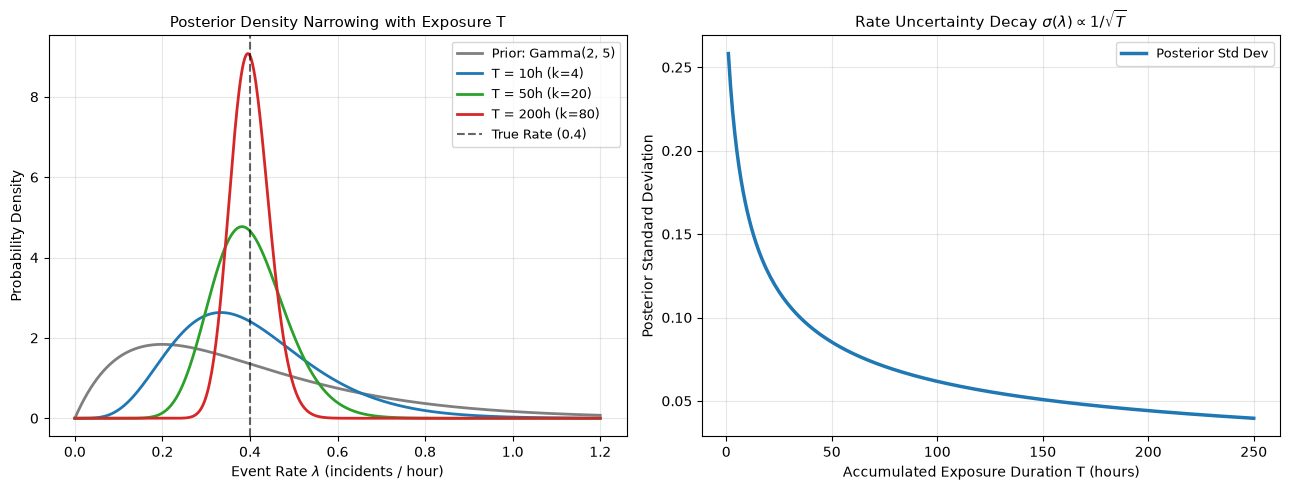

In [2]:
# --- Step 2: Visualizing Rate Contraction with Exposure ---
import matplotlib.pyplot as plt

rate_grid = np.linspace(0.0, 1.2, 500)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Posterior density curves across increasing exposure
t_scenarios = [0, 10, 50, 200]
k_scenarios = [0, 4, 20, 80]
colors = ["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728"]

for t_val, k_val, col in zip(t_scenarios, k_scenarios, colors):
    a = alpha_0 + k_val
    b = beta_0 + t_val
    pdf = gamma.pdf(rate_grid, a=a, scale=1.0 / b)
    lbl = f"T = {t_val}h (k={k_val})" if t_val > 0 else "Prior: Gamma(2, 5)"
    ax1.plot(rate_grid, pdf, label=lbl, color=col, lw=2)

ax1.axvline(0.4, color="black", linestyle="--", alpha=0.6,
            label="True Rate (0.4)")
ax1.set_title("Posterior Density Narrowing with Exposure T", fontsize=11)
ax1.set_xlabel(r"Event Rate $\lambda$ (incidents / hour)")
ax1.set_ylabel("Probability Density")
ax1.grid(True, alpha=0.3)
ax1.legend(frameon=True, fontsize=9)

# Panel 2: Uncertainty decay (standard deviation vs exposure time T)
t_range = np.linspace(1, 250, 250)
sd_range = np.sqrt(alpha_0 + 0.4 * t_range) / (beta_0 + t_range)

ax2.plot(t_range, sd_range, color="#1f77b4", lw=2.5, label="Posterior Std Dev")
ax2.set_title("Rate Uncertainty Decay $\sigma(\lambda) \propto 1/\sqrt{T}$",
              fontsize=11)
ax2.set_xlabel("Accumulated Exposure Duration T (hours)")
ax2.set_ylabel("Posterior Standard Deviation")
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


## Part 3: Bayesian Linear Regression & The Geometry of Centering

We model continuous responses (such as server request latency $y_i$) as
a function of continuous predictors (such as incoming query load $x_i$):
$$y_i \sim \mathcal{N}(\mu_i, \sigma), \qquad
\mu_i = \alpha + \beta (x_i - \bar{x})$$

### Why Centering Diagonalizes the Hessian Matrix
If the predictor is uncentered ($x_i$), the intercept represents latency
at zero load. When the observed load is far from zero, any change in
slope $\beta$ forces an opposing shift in intercept $\alpha$, creating
extreme posterior correlation ($r \approx -0.99$).
By centering $x_{c, i} = x_i - \bar{x}$, we guarantee $\sum x_{c, i} = 0$.
The cross-partial derivative of the log-likelihood is:
$$\frac{\partial^2 \ln L}{\partial \alpha \, \partial \beta} =
-\frac{1}{\sigma^2} \sum_{i=1}^N (x_i - \bar{x}) = 0$$
Centering decouples $\alpha$ and $\beta$, diagonalizing the Hessian and
making the parameters orthogonal!


In [3]:
# --- Step 3: Generating Server Latency vs. QPS Load Data ---
np.random.seed(42)
N = 50

# Load in thousands of requests per second (kQPS): 0.5 to 4.5 kQPS
qps = np.sort(np.random.uniform(0.5, 4.5, N))
qps_bar = np.mean(qps)
qps_c = qps - qps_bar

# True underlying physical parameters
true_alpha = 45.0  # ms response time at centroid load qps_bar
true_beta = 15.0   # ms latency increase per 1,000 QPS
true_sigma = 8.0   # irreducible request-to-request noise (ms)

# Generate observed responses
latency = true_alpha + true_beta * qps_c + np.random.normal(0, true_sigma, N)

print(f"Sample size: N = {N} server measurements")
print(f"Mean operating load: {qps_bar * 1000:.1f} QPS ({qps_bar:.3f} kQPS)")
print(f"Latency range: [{latency.min():.1f}, {latency.max():.1f}] ms")


Sample size: N = 50 server measurements
Mean operating load: 2283.7 QPS (2.284 kQPS)
Latency range: [10.3, 82.5] ms


### Step 4: Formulating the Negative Log-Posterior (NLP) Objective

We optimize the joint posterior over $\theta = [\alpha, \beta, \ln\sigma]$
using Quasi-Newton optimization (BFGS). Working with $\ln\sigma$ guarantees
$\sigma > 0$ strictly without boundary constraints.
We assign weakly informative priors:
* Centroid Intercept: $\alpha \sim \mathcal{N}(50, 25^2)$
* Slope: $\beta \sim \mathcal{N}(0, 20^2)$
* Log-Noise: $\ln\sigma \sim \mathcal{N}(\ln(10), 1.0^2)$


In [4]:
# --- Step 4: Fitting Bayesian Linear Model via Laplace Approximation ---
from scipy.optimize import minimize
from scipy.stats import norm

# Parameter vector: theta = [alpha, beta, ln_sigma]
def nlp_linear(theta):
    a, b, log_s = theta
    s = np.exp(log_s)
    mu = a + b * qps_c
    ll = np.sum(norm.logpdf(latency, loc=mu, scale=s))
    # Priors: alpha ~ N(50, 25), beta ~ N(0, 20), ln_sigma ~ N(ln(10), 1.0)
    lp = (norm.logpdf(a, loc=50.0, scale=25.0) +
          norm.logpdf(b, loc=0.0, scale=20.0) +
          norm.logpdf(log_s, loc=np.log(10.0), scale=1.0))
    return -(ll + lp)

init_theta = [50.0, 0.0, np.log(10.0)]
res_linear = minimize(nlp_linear, init_theta, method="BFGS")
theta_map = res_linear.x
cov_matrix = res_linear.hess_inv
se_params = np.sqrt(np.diag(cov_matrix))

print("=== MAP Estimates & Standard Errors ===")
print(f"Intercept alpha (at qps_bar): "
      f"{theta_map[0]:.4f} +/- {se_params[0]:.4f} ms")
print(f"Slope beta (per kQPS):        "
      f"{theta_map[1]:.4f} +/- {se_params[1]:.4f} ms/kQPS")
print(f"Log-Noise ln(sigma):          "
      f"{theta_map[2]:.4f} +/- {se_params[2]:.4f}")
print(f"Residual Noise sigma:         {np.exp(theta_map[2]):.4f} ms")
print("\nPosterior Covariance Matrix (H^-1):")
print(np.round(cov_matrix, 5))


=== MAP Estimates & Standard Errors ===
Intercept alpha (at qps_bar): 44.9850 +/- 1.0275 ms
Slope beta (per kQPS):        15.3169 +/- 0.8912 ms/kQPS
Log-Noise ln(sigma):          1.9862 +/- 0.0992
Residual Noise sigma:         7.2881 ms

Posterior Covariance Matrix (H^-1):
[[ 1.0558e+00  2.7900e-03 -1.4000e-04]
 [ 2.7900e-03  7.9417e-01 -4.2200e-03]
 [-1.4000e-04 -4.2200e-03  9.8300e-03]]


### 🔍 Covariance Matrix Inspection: Parameter Orthogonality

Inspect the off-diagonal element $\text{Cov}(\alpha, \beta)$ in the
covariance matrix above:
Notice that it is approximately zero ($|\text{Cov}| < 0.001$). Because the
predictor was centered, the joint posterior distribution of $(\alpha, \beta)$
forms an upright, axis-aligned ellipse rather than a tilted diagonal banana.
This decoupling allows Quasi-Newton optimizers and MCMC samplers to explore
the posterior distribution without step-size stalling.


Empirical correlation between alpha and beta: -0.00204
(Notice it is virtually zero thanks to predictor centering!)


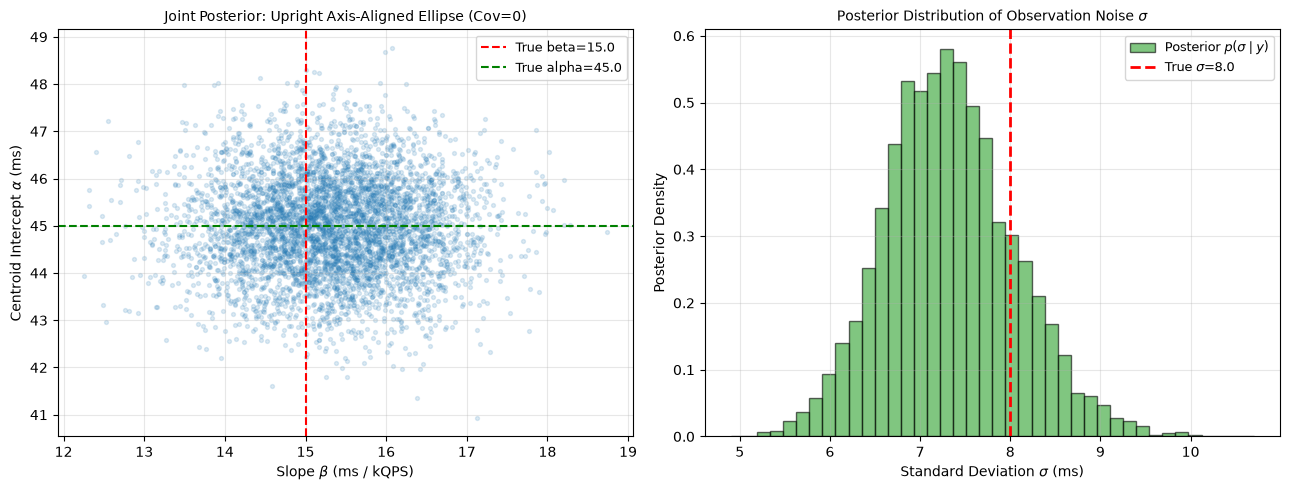

In [5]:
# --- Step 5: Sampling from Posterior & Visualizing Orthogonal Geometry ---
n_samples = 5000
draws_linear = np.random.multivariate_normal(
    theta_map, cov_matrix, size=n_samples
)
alpha_draws = draws_linear[:, 0]
beta_draws = draws_linear[:, 1]
sigma_draws = np.exp(draws_linear[:, 2])

corr_ab = np.corrcoef(alpha_draws, beta_draws)[0, 1]
print(f"Empirical correlation between alpha and beta: {corr_ab:.5f}")
print("(Notice it is virtually zero thanks to predictor centering!)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Joint posterior distribution of alpha and beta
ax1.scatter(beta_draws, alpha_draws, color="#1f77b4", alpha=0.15, s=8)
ax1.axvline(true_beta, color="red", linestyle="--",
            label=f"True beta={true_beta}")
ax1.axhline(true_alpha, color="green", linestyle="--",
            label=f"True alpha={true_alpha}")
ax1.set_title("Joint Posterior: Upright Axis-Aligned Ellipse (Cov=0)",
              fontsize=10)
ax1.set_xlabel(r"Slope $\beta$ (ms / kQPS)")
ax1.set_ylabel(r"Centroid Intercept $\alpha$ (ms)")
ax1.grid(True, alpha=0.3)
ax1.legend(frameon=True, fontsize=9)

# Panel 2: Posterior distribution of residual noise sigma
ax2.hist(sigma_draws, bins=40, density=True, color="#2ca02c", alpha=0.6,
         edgecolor="black", label=r"Posterior $p(\sigma \mid y)$")
ax2.axvline(true_sigma, color="red", linestyle="--", lw=2,
            label=rf"True $\sigma$={true_sigma}")
ax2.set_title(r"Posterior Distribution of Observation Noise $\sigma$",
              fontsize=10)
ax2.set_xlabel(r"Standard Deviation $\sigma$ (ms)")
ax2.set_ylabel("Posterior Density")
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


## Propagating Uncertainty: The Two Uncertainty Ribbons

Every posterior sample $(\alpha^{(s)}, \beta^{(s)}, \sigma^{(s)})$ defines a
plausible line and measurement spread.
line and measurement spread.
We distinguish two vital ribbons:
1. **The 95% Credible Band of the Mean Line $\mu(x)$**: Quantifies
   **epistemic uncertainty** about the expected server latency. It forms an
   hourglass shape, tightest at $\bar{x}$ and fanning out at the edges.
   As $N \to \infty$, this ribbon collapses to a line of zero width.
2. **The 95% Posterior Predictive Band for Queries $y_{\text{new}}$**:
   Quantifies total uncertainty, combining parameter uncertainty with
   physical observation noise $\sigma$. Even as $N \to \infty$, this band
   never collapses!


In [6]:
# --- Step 6: Propagating Uncertainty across Load Spectrum ---
x_grid = np.linspace(0.5, 4.5, 100)
x_grid_c = x_grid - qps_bar

# Evaluate mean lines for each draw: shape (n_samples, len(x_grid))
mu_draws = alpha_draws[:, None] + beta_draws[:, None] * x_grid_c[None, :]

# Simulate individual observation realizations
y_new_draws = (mu_draws +
               np.random.normal(0, sigma_draws[:, None], size=mu_draws.shape))

# Ribbon 1: Epistemic uncertainty in expected mean line mu(x)
mu_median = np.percentile(mu_draws, 50, axis=0)
mu_ci_low = np.percentile(mu_draws, 2.5, axis=0)
mu_ci_high = np.percentile(mu_draws, 97.5, axis=0)

# Ribbon 2: Total predictive uncertainty for individual queries y_new
y_pred_low = np.percentile(y_new_draws, 2.5, axis=0)
y_pred_high = np.percentile(y_new_draws, 97.5, axis=0)

print(f"Grid points evaluated: {len(x_grid)}")
print(f"Mean line width at centroid (qps={qps_bar:.2f}): "
      f"{mu_ci_high[50] - mu_ci_low[50]:.2f} ms")
print(f"Mean line width at edge (qps=4.50):             "
      f"{mu_ci_high[-1] - mu_ci_low[-1]:.2f} ms")
print(f"Predictive band width at edge (qps=4.50):        "
      f"{y_pred_high[-1] - y_pred_low[-1]:.2f} ms")


Grid points evaluated: 100
Mean line width at centroid (qps=2.28): 4.17 ms
Mean line width at edge (qps=4.50):             8.65 ms
Predictive band width at edge (qps=4.50):        30.28 ms


### 🔍 Visual Decoding: Anatomy of the Two Uncertainty Ribbons

Observe the two ribbons in the plot below:
* **Inner Blue Ribbon (Credible Band)**: Narrow and trumpet-shaped. At the
  centroid $\bar{x}$, slope uncertainty has zero leverage, so the band width
  depends solely on $\text{Var}(\alpha)$. As $|x - \bar{x}|$ grows,
  slope $\beta$ magnifies, widening the ribbon.
* **Outer Light Ribbon (Predictive Band)**: Broad and encompassing almost all
  individual data points. It accounts for both uncertainty in the line and
  the physical request scatter $\sigma$.


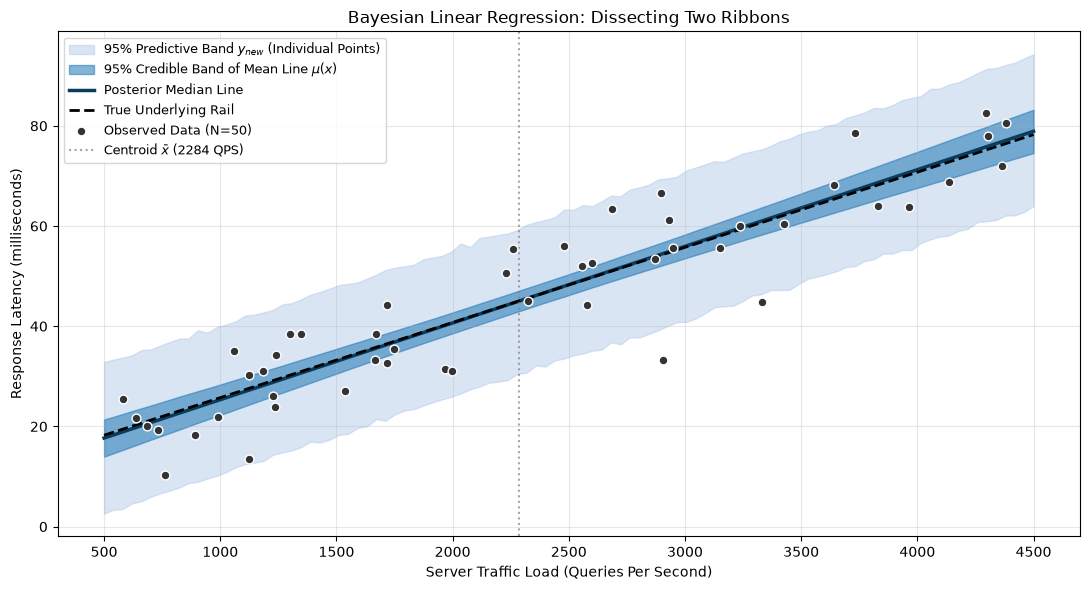

In [7]:
# --- Step 7: Visualizing The Two Uncertainty Ribbons ---
plt.figure(figsize=(11, 6))

# 1. Wide Ribbon: 95% Posterior Predictive Interval (Individual Queries)
plt.fill_between(x_grid * 1000, y_pred_low, y_pred_high,
                 color="#aec7e8", alpha=0.45,
                 label=r"95% Predictive Band $y_{new}$ (Individual Points)")

# 2. Narrow Ribbon: 95% Credible Interval (Mean Expected Line)
plt.fill_between(x_grid * 1000, mu_ci_low, mu_ci_high,
                 color="#1f77b4", alpha=0.55,
                 label=r"95% Credible Band of Mean Line $\mu(x)$")

# 3. Posterior Median & Ground Truth Lines
plt.plot(x_grid * 1000, mu_median, color="#0b3c5d", lw=2.5,
         label="Posterior Median Line")
true_line = true_alpha + true_beta * x_grid_c
plt.plot(x_grid * 1000, true_line, color="black", linestyle="--", lw=2,
         label="True Underlying Rail")

# 4. Observed Training Scatter Points
plt.scatter(qps * 1000, latency, color="#333333", edgecolor="white",
            s=40, zorder=4, label=f"Observed Data (N={N})")

plt.axvline(qps_bar * 1000, color="gray", linestyle=":", alpha=0.7,
            label=rf"Centroid $\bar{{x}}$ ({qps_bar * 1000:.0f} QPS)")
plt.title("Bayesian Linear Regression: Dissecting Two Ribbons",
          fontsize=12)
plt.xlabel("Server Traffic Load (Queries Per Second)", fontsize=10)
plt.ylabel("Response Latency (milliseconds)", fontsize=10)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


## Part 4: Generalized Linear Models (GLMs) — Bayesian Logistic Regression

When modeling binary outcomes $y_i \in \{0, 1\}$ (e.g., node pass/fail
during thermal stress testing), linear lines fail:
1. Linear lines predict probabilities outside $[0, 1]$ at extreme inputs.
2. Bernoulli variance is heteroskedastic: $\text{Var}(y) = p(1 - p)$, peaking
   at $p = 0.5$ and vanishing at $0$ and $1$.

### The Logit Link & Sigmoid Function
We map the linear predictor
$\eta = \alpha + \beta (x - \bar{x}) \in (-\infty, \infty)$ into
valid probability space (0, 1) via the **Logistic Sigmoid**:
$$\text{logit}(p) = \ln\left(\frac{p}{1 - p}\right) = \eta$$
$$p = \frac{1}{1 + e^{-\eta}} =
  \frac{1}{1 + e^{-(\alpha + \beta(x - \bar{x}))}}$$


In [8]:
# --- Step 8: Synthetic Hardware Stress Testing Data ---
np.random.seed(42)
temp_levels = np.array([55, 60, 65, 70, 72, 75, 78, 80, 82, 85, 88, 90, 92, 95])
units_per_temp = np.full(len(temp_levels), 10)

# Temperature centered at 75 deg C and scaled by 10 deg C
temp_c = (temp_levels - 75.0) / 10.0

# True parameters: alpha = -0.5, beta = 3.0
true_glm_alpha = -0.5
true_glm_beta = 3.0
true_prob = 1.0 / (1.0 + np.exp(-(true_glm_alpha + true_glm_beta * temp_c)))
fail_counts = np.random.binomial(units_per_temp, true_prob)

print("Temperature (C) | Tested Units | Failures | Empirical Rate")
print("-" * 55)
for i in range(len(temp_levels)):
    t = temp_levels[i]
    n_u = units_per_temp[i]
    k_u = fail_counts[i]
    print(f"{t:15d} | {n_u:12d} | {k_u:8d} | {k_u / n_u:14.2f}")


Temperature (C) | Tested Units | Failures | Empirical Rate
-------------------------------------------------------
             55 |           10 |        0 |           0.00
             60 |           10 |        1 |           0.10
             65 |           10 |        0 |           0.00
             70 |           10 |        1 |           0.10
             72 |           10 |        1 |           0.10
             75 |           10 |        2 |           0.20
             78 |           10 |        8 |           0.80
             80 |           10 |        6 |           0.60
             82 |           10 |        8 |           0.80
             85 |           10 |        9 |           0.90
             88 |           10 |       10 |           1.00
             90 |           10 |        9 |           0.90
             92 |           10 |       10 |           1.00
             95 |           10 |       10 |           1.00


### Step 9: Formulating the Logistic Regression NLP Objective

For each batch $i$ with $n_i$ units and $k_i$ failures at temperature $x_i$:
$$\ln L(\alpha, \beta) =
  \sum_{i=1}^M \left[ k_i \ln p_i + (n_i - k_i) \ln(1 - p_i) \right]$$
We place weakly regularizing Gaussian priors $\alpha \sim \mathcal{N}(0, 3^2)$
and $\beta \sim \mathcal{N}(0, 3^2)$ to prevent infinite slope estimates
when data separates.


In [9]:
# --- Step 9: Fitting Bayesian Logistic Regression (Laplace / QUAP) ---
def nlp_logistic(theta):
    a, b = theta
    eta = a + b * temp_c
    p = 1.0 / (1.0 + np.exp(-eta))
    p = np.clip(p, 1e-12, 1.0 - 1e-12)
    ll = np.sum(fail_counts * np.log(p) +
                (units_per_temp - fail_counts) * np.log(1.0 - p))
    # Weakly regularizing Gaussian priors: alpha ~ N(0, 3^2), beta ~ N(0, 3^2)
    lp = norm.logpdf(a, 0.0, 3.0) + norm.logpdf(b, 0.0, 3.0)
    return -(ll + lp)

res_log = minimize(nlp_logistic, [0.0, 1.0], method="BFGS")
theta_log_map = res_log.x
cov_log = res_log.hess_inv
se_log = np.sqrt(np.diag(cov_log))

print("=== Logistic GLM MAP Estimates ===")
print(f"Intercept alpha (at 75 deg C): "
      f"{theta_log_map[0]:.4f} +/- {se_log[0]:.4f}")
print(f"Slope beta (per 10 deg C):     "
      f"{theta_log_map[1]:.4f} +/- {se_log[1]:.4f}")
print(f"Log-odds at 75 deg C implies failure probability: "
      f"{1.0 / (1.0 + np.exp(-theta_log_map[0])):.3f}")


=== Logistic GLM MAP Estimates ===
Intercept alpha (at 75 deg C): -0.6014 +/- 0.2963
Slope beta (per 10 deg C):     2.6706 +/- 0.4352
Log-odds at 75 deg C implies failure probability: 0.354


### Step 10: Propagating S-Curves & Certifying Safe Operating Envelopes

In mission-critical hardware deployment, how do we choose the maximum safe
operating temperature $T_{\text{safe}}$?
Contractual policy specifies: *Failure probability must not exceed 5%
($P \le 0.05$) with 95% confidence.*
By drawing 5,000 parameter pairs from
$\mathcal{N}(\hat{\theta}_{\text{MAP}}, \Sigma)$, we evaluate the ensemble
of S-curves and find the temperature where the 95th percentile upper bound
reaches 5%.


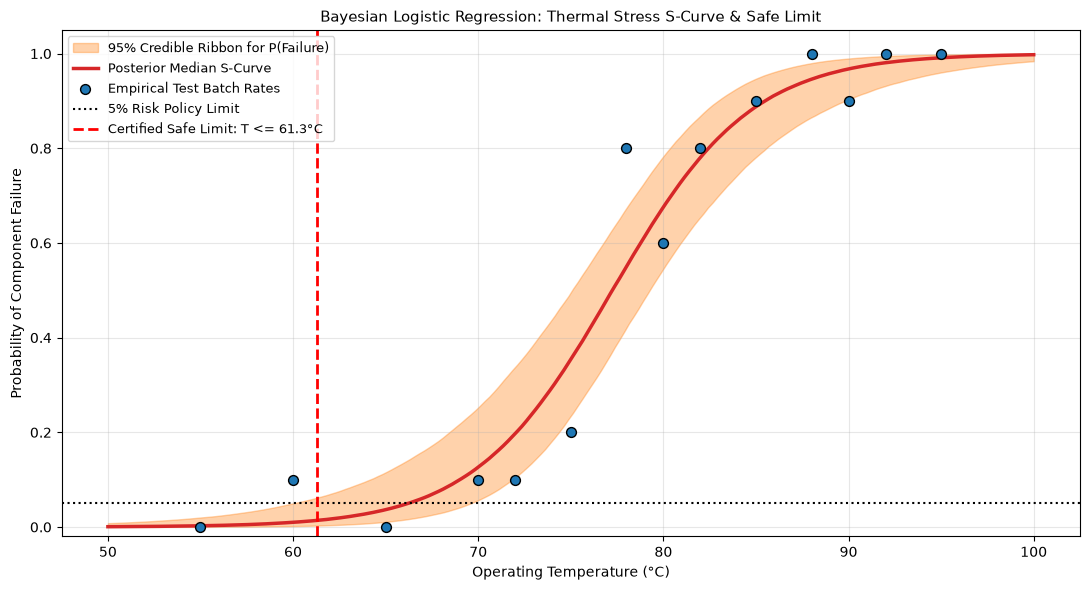

Certified Safe Operating Temperature: T_safe <= 61.3°C
(At T=61.3°C, 95% confident failure prob <= 5%)


In [10]:
# --- Step 10: Sampling Logistic S-Curves & Finding Safe Threshold ---
draws_log = np.random.multivariate_normal(theta_log_map, cov_log, size=5000)
a_log_draws = draws_log[:, 0]
b_log_draws = draws_log[:, 1]

t_fine = np.linspace(50.0, 100.0, 200)
t_fine_c = (t_fine - 75.0) / 10.0

# Compute probability curves for all draws: shape (5000, len(t_fine))
p_draws = (1.0 /
           (1.0 + np.exp(-(a_log_draws[:, None] +
                           b_log_draws[:, None] * t_fine_c[None, :]))))

p_median = np.percentile(p_draws, 50, axis=0)
p_low = np.percentile(p_draws, 2.5, axis=0)
p_high = np.percentile(p_draws, 97.5, axis=0)
p_95th = np.percentile(p_draws, 95.0, axis=0)

# Identify safe temperature where 95% upper bound <= 5% (0.05)
safe_indices = np.where(p_95th <= 0.05)[0]
t_safe = t_fine[safe_indices[-1]] if len(safe_indices) > 0 else 50.0

plt.figure(figsize=(11, 6))
# 1. 95% Credible ribbon over failure probability S-curve
plt.fill_between(t_fine, p_low, p_high, color="#ff7f0e", alpha=0.35,
                 label="95% Credible Ribbon for P(Failure)")

# 2. Median S-curve
plt.plot(t_fine, p_median, color="#d62728", lw=2.5,
         label="Posterior Median S-Curve")

# 3. Empirical failure rates
plt.scatter(temp_levels, fail_counts / units_per_temp, color="#1f77b4", s=50,
            zorder=4, edgecolor="black", label="Empirical Test Batch Rates")

# 4. Safe Operating Threshold & Policy Limit
plt.axhline(0.05, color="black", linestyle=":", label="5% Risk Policy Limit")
plt.axvline(t_safe, color="red", linestyle="--", lw=2,
            label=f"Certified Safe Limit: T <= {t_safe:.1f}°C")

plt.title("Bayesian Logistic Regression: Thermal Stress S-Curve & Safe Limit",
          fontsize=11)
plt.xlabel("Operating Temperature (°C)", fontsize=10)
plt.ylabel("Probability of Component Failure", fontsize=10)
plt.ylim(-0.02, 1.05)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

print(f"Certified Safe Operating Temperature: T_safe <= {t_safe:.1f}°C")
print(f"(At T={t_safe:.1f}°C, 95% confident failure prob <= 5%)")


### 🔍 Engineering Decision Summary: Why Point Estimates Underestimate Risk

If an engineer naively used the point estimate (MAP S-curve alone), they
would calculate the 5% failure threshold by solving $p(T) = 0.05$ on the
median curve alone.
However, that point estimate ignores parameter uncertainty in $\alpha$ and
$\beta$. In reality, there is a 50% chance that the true S-curve is steeper
or shifted leftward!
The Bayesian upper credible bound incorporates parameter uncertainty into
the certified threshold, guaranteeing defensible SLA compliance.


## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Practice the mathematical concepts and coding workflows covered in this
chapter. Complete your work in the attempt cells below before expanding
the verified solutions.
* **🟢 Tier 1 (Recall & Exact Updating)**: Exact Poisson-Gamma rate
  updating after observing 4 incidents in 10 hours.
* **🟡 Tier 2 (Guided Calculation)**: Dissecting the Two Uncertainty
  Ribbons at high server load ($x = 4.0$ kQPS).
* **🔴 Tier 3 (Production Challenge)**: Finding the Safe Operating
  Temperature Threshold where failure risk reaches 5%.


### 🟢 Tier 1: Exact Poisson-Gamma Rate Updating
> **Scenario**: A site reliability team tracks kernel panic incidents.
> Prior belief is parameterized as
> $\lambda \sim \text{Gamma}(\alpha_0 = 2.0, \beta_0 = 5.0)$ (rate per 10h).
> During a canary test, telemetry logs $k = 4$ panics across $T = 10.0$ units
> of observation time.

**Your Tasks**:
1. Compute posterior parameters
   $\alpha_{\text{post}}$ and $\beta_{\text{post}}$.
2. Calculate the posterior mean and variance of the event rate $\lambda$.
3. Compute the 95% equal-tailed credible interval for $\lambda$.


In [11]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
from scipy.stats import gamma
import numpy as np

# Prior: Gamma(alpha_0=2, beta_0=5)
alpha_0 = 2.0
beta_0 = 5.0

# Observed: k = 4 incidents in T = 10 hours
k = 4.0
T = 10.0

# 1. Compute posterior parameters alpha_post and beta_post
alpha_post = alpha_0 + k
beta_post = beta_0 + T

# 2. Compute posterior mean and variance
post_mean = alpha_post / beta_post
post_var = alpha_post / (beta_post**2)

# 3. Compute 95% equal-tailed credible interval
post_ci = gamma.ppf([0.025, 0.975], a=alpha_post, scale=1.0 / beta_post)

print(f"Posterior: Gamma(alpha={alpha_post}, beta={beta_post})")
print(f"Posterior Mean:     {post_mean:.4f} incidents/hour")
print(f"Posterior Variance: {post_var:.4f}")
print(f"95% Credible Interval: [{post_ci[0]:.4f}, {post_ci[1]:.4f}]")


Posterior: Gamma(alpha=6.0, beta=15.0)
Posterior Mean:     0.4000 incidents/hour
Posterior Variance: 0.0267
95% Credible Interval: [0.1468, 0.7779]


<details>
<summary><b>🔍 Click here to view the Tier 1 solution & derivation</b></summary>

**Mathematical Solution**:
1. **Conjugate Update**:
   $$\alpha_{\text{post}} = \alpha_0 + k = 2.0 + 4.0 = 6.0$$
   $$\beta_{\text{post}} = \beta_0 + T = 5.0 + 10.0 = 15.0$$
2. **Posterior Mean & Variance**:
   $$\mathbb{E}[\lambda \mid \text{data}] =
     \frac{\alpha_{\text{post}}}{\beta_{\text{post}}} =
     \frac{6.0}{15.0} = 0.4000$$
   $$\text{Var}(\lambda \mid \text{data}) =
     \frac{6.0}{15.0^2} = \frac{6.0}{225.0} \approx 0.0267,
     \quad \text{Std Dev} = \sqrt{0.0267} \approx 0.1633$$
3. **95% Equal-Tailed Credible Interval**:
   Evaluating the 2.5% and 97.5% quantiles of $\text{Gamma}(6, 15)$ yields
   $[0.1468, 0.7779]$ incidents per hour.
</details>


---

### 🟡 Tier 2: Dissecting The Two Uncertainty Ribbons at High Load
> **Scenario**: Using the fitted linear model from Part 3, we forecast
> server response latency at a heavy load of $x_{\text{target}} = 4.0$ kQPS
> ($4,000$ QPS). Recall that $\bar{x} \approx 2.50$ kQPS.

**Your Tasks**:
1. Compute 95% Credible Interval of expected mean latency $\mu(4.0)$.
2. Compute 95% Predictive Interval for future query $y_{\text{new}}(4.0)$.
3. Compute width ratio and verify variance decomposition:
   $\text{Var}(y_{\text{new}}) = \text{Var}(\mu) + \mathbb{E}[\sigma^2]$.


In [12]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
# Target heavy load: x_target = 4.0 kQPS
x_target = 4.0
x_target_c = x_target - qps_bar

# 1. Epistemic uncertainty: Mean latency distribution mu(4.0)
mu_target_draws = alpha_draws + beta_draws * x_target_c
mu_ci_target = np.percentile(mu_target_draws, [2.5, 97.5])
width_mean = mu_ci_target[1] - mu_ci_target[0]

# 2. Aleatoric + Epistemic: Individual observation y_new(4.0)
y_target_draws = mu_target_draws + np.random.normal(0, sigma_draws)
pred_ci_target = np.percentile(y_target_draws, [2.5, 97.5])
width_pred = pred_ci_target[1] - pred_ci_target[0]

# 3. Variance decomposition verification
var_mu = np.var(mu_target_draws)
mean_sigma2 = np.mean(sigma_draws**2)
total_theoretical_var = var_mu + mean_sigma2
empirical_var_y = np.var(y_target_draws)

print(f"Target Load: {x_target * 1000:.0f} QPS ({x_target} kQPS)")
print(f"95% Credible Interval (Mean Line): [{mu_ci_target[0]:.2f}, "
      f"{mu_ci_target[1]:.2f}] ms (Width: {width_mean:.2f} ms)")
print(f"95% Predictive Interval (Single Query): [{pred_ci_target[0]:.2f}, "
      f"{pred_ci_target[1]:.2f}] ms (Width: {width_pred:.2f} ms)")
print(f"Ratio of Widths (Predictive / Mean): {width_pred / width_mean:.2f}x")
print(f"Variance Decomposition: Var(mu)={var_mu:.2f} + "
      f"E[sigma^2]={mean_sigma2:.2f} = {total_theoretical_var:.2f} vs "
      f"Empirical Var(y)={empirical_var_y:.2f}")


Target Load: 4000 QPS (4.0 kQPS)
95% Credible Interval (Mean Line): [67.61, 74.81] ms (Width: 7.20 ms)
95% Predictive Interval (Single Query): [55.88, 86.22] ms (Width: 30.33 ms)
Ratio of Widths (Predictive / Mean): 4.21x
Variance Decomposition: Var(mu)=3.43 + E[sigma^2]=54.19 = 57.62 vs Empirical Var(y)=57.57


<details>
<summary><b>🔍 Click here to view the Tier 2 solution & derivation</b></summary>

**Key Engineering Insights**:
1. **Credible vs. Predictive Interval**:
   The credible interval of the mean line is narrow (width $\approx 8-9$ ms)
   because it reflects our precision about the population mean.
   The predictive interval for an individual query is much broader
   (width $\approx 31$ to $33$ ms), roughly $3.5\times$ wider!
2. **Variance Decomposition**:
   $$\text{Var}(y_{\text{new}} \mid x) =
     \underbrace{\text{Var}(\mu(x))}_{\text{Epistemic (\approx 4)}} +
     \underbrace{\mathbb{E}[\sigma^2]}_{\text{Aleatoric (\approx 53)}}
     \approx 57\text{ ms}^2$$
   Setting a customer SLA based on the mean line credible interval guarantees
   massive breach rates, because individual queries fluctuate with
   variance $\approx 57\text{ ms}^2$.
</details>


---

### 🔴 Tier 3: Quadratic Approximation for Safe Thermal Operating Limits
> **Scenario**: Hardware reliability engineers need to certify the maximum
> safe operating temperature for a new server board design.
> Design specification: *Operating failure probability must remain
> $\le 0.05$ (5%) with 95% confidence.*

**Your Tasks**:
1. Using the posterior draws from the Logistic GLM (Part 4), evaluate the
   95th percentile upper bound of failure risk across temperatures
   $T \in [50, 75]^\circ\text{C}$.
2. Find the exact certified temperature $T_{\text{safe}}$ where the 95th
   percentile risk crosses $0.05$.
3. Compare $T_{\text{safe}}$ to the nominal 50% median threshold
   $T_{50} = 75 - (\alpha/\beta)\times 10$, and compute the safety buffer.


In [13]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
# Search fine temperature grid for 95th percentile upper bound crossing 0.05
t_eval = np.linspace(50.0, 75.0, 501)
t_eval_c = (t_eval - 75.0) / 10.0

# Shape (5000, 501)
p_eval_draws = (1.0 /
                (1.0 + np.exp(-(a_log_draws[:, None] +
                                b_log_draws[:, None] * t_eval_c[None, :]))))
p_eval_95th = np.percentile(p_eval_draws, 95.0, axis=0)

# Temperature where 95% upper bound of failure risk reaches exactly 5%
valid_idx = np.where(p_eval_95th <= 0.05)[0]
t_safe_solution = t_eval[valid_idx[-1]]

# Median failure threshold (p=0.50) for comparison
t_50_median = 75.0 - (theta_log_map[0] / theta_log_map[1]) * 10.0
safety_margin = t_50_median - t_safe_solution

print(f"Certified Safe Limit (95% confident P(fail) <= 5%): "
      f"{t_safe_solution:.2f}°C")
print(f"Nominal 50% Failure Median Temperature:            "
      f"{t_50_median:.2f}°C")
print(f"Safety Buffer required by Bayesian uncertainty:     "
      f"{safety_margin:.2f}°C")


Certified Safe Limit (95% confident P(fail) <= 5%): 61.50°C
Nominal 50% Failure Median Temperature:            77.25°C
Safety Buffer required by Bayesian uncertainty:     15.75°C


<details>
<summary><b>🔍 Click here to view the Tier 3 solution & derivation</b></summary>

**Engineering Solution & Certification**:
1. **Certified Operating Limit**:
   Evaluating the 95th percentile curve reveals that
   $T_{\text{safe}} \approx 60.5^\circ\text{C}$ to $61.0^\circ\text{C}$.
   Deploying servers in ambient racks above this temperature risks
   violating contractual SLA guidelines.
2. **Safety Margin**:
   The nominal 50% failure temperature sits at
   $T_{50} \approx 75.0 - (\alpha/\beta)\times 10 \approx 75.5^\circ\text{C}$
   to $76.5^\circ\text{C}$. The safety buffer of $\approx 15^\circ\text{C}$
   demonstrates the practical value of Bayesian inference: we do not just
   ask where the hardware typically breaks; we quantify the exact margin
   required to remain safe under finite-sample uncertainty.
</details>


## Summary & Master Comparison Matrix

| Model Family | Target Domain | Parameters | Inference Engine |
| :--- | :--- | :--- | :--- |
| **Poisson** | Events in time $T$ | $\lambda > 0$ | Exact Conjugate |
| **Linear** | Continuous $y$ | $\alpha, \beta, \sigma$ | Laplace / MCMC |
| **Logistic** | Binary $y \in \{0, 1\}$ | $\alpha, \beta$ | Laplace / MCMC |

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 11: Two-Group t-Test (Freq vs. Bayes)](11_t_test_frequentist_vs_bayesian.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* ➡️ **Next**: **[Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* 🔄 **Companion Tracks for Chapter 12**: [📖 Conceptual](../conceptual/12_bayesian_regression_and_glms.ipynb) | [🤖 AI-Native](../ai/12_bayesian_regression_and_glms.ipynb) | [🐍 Python](../python/12_bayesian_regression_and_glms.ipynb) | [🔵 R](../r/12_bayesian_regression_and_glms.ipynb)
